In [1]:
import numpy
import pandas
import seaborn

from matplotlib import pyplot

from fitting import TIMESERIES_TABLE_PATH
from realistic import PARAMS

/home/anm1u24/.cache/pypoetry/virtualenvs/slrv-m033ZCIA-py3.13/lib/python3.13/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/anm1u24/.cache/pypoetry/virtualenvs/slrv-m033ZCIA-py3.13/lib/python3.13/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/anm1u24/.cache/pypoetry/virtualenvs/slrv-m033ZCIA-py3.13/lib/python3.13/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 366 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


In [2]:
pyplot.rcParams["figure.figsize"] = [12.8, 9.6]

In [3]:
def err(obs, model):
    scale = numpy.abs(obs)
    scale[scale == 0] = 1
    return numpy.abs(obs - model) / scale

In [4]:
params = {
    'a': 'fitted_a',
    'b': 'fitted_b',
    'e': 'fitted_e',
    'periapsis_phase': 'fitted_periapsis_phase',
    'Macc': 'fitted_Macc',
    'Porb': 'fitted_porb',
    'tau_eff': 'fitted_tau_eff',
}

In [5]:
results = pandas.read_pickle(TIMESERIES_TABLE_PATH)

In [6]:
results

,a,e,periapsis_phase,Macc,Porb,tau_eff,Mcomp,Rcomp,b,rv,...,baseline,pristine idx,realistic_idx,fitted_a,fitted_b,fitted_Macc,fitted_e,fitted_periapsis_phase,fitted_porb,fitted_tau_eff
0,0.828643,0,0,5.000000,112.479615,0.171279,1.0,1.0,7.755102,"[-112813.43149200453, 171713.10356524022, 7652...",...,365,18607,95374,0.828648,7.793161,5.000123,0.000037,1.785921,112.479578,0.170747
1,2.222996,0,0,14.375000,308.744357,0.250170,1.0,1.0,1.020408,"[-287770.4812514142, 277367.13297361974, -2647...",...,1095,23498,25716,2.223191,0.996755,14.378739,0.000034,2.628511,308.747247,0.250393
2,0.719686,0,0,27.916667,41.470436,0.062670,1.0,1.0,4.897959,"[858392.2149381506, -675636.0203199809, -63666...",...,1095,17381,56540,0.539949,1.748630,11.210968,0.709972,6.281106,41.471761,0.119605
3,0.268270,0,0,27.916667,9.438032,0.051344,1.0,1.0,4.489796,"[-1477722.424661582, -1316408.2297169296, 3622...",...,1825,9321,43205,0.624228,3.081793,23.161076,0.473968,3.091812,36.648446,0.089648
4,3.906940,0,0,20.625000,606.562380,0.317456,1.0,1.0,0.204082,"[260227.97739083847, -266404.0489099596]",...,365,25758,50800,4.630458,1.647708,19.807466,0.159075,4.015301,797.856558,0.316624
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,2.222996,0,0,11.250000,345.890430,0.204271,1.0,1.0,3.877551,"[-166050.52902181106, -235214.00924146824, -23...",...,1825,23845,91886,2.222995,3.807684,11.249982,0.000019,3.943224,345.890452,0.207430
4996,0.719686,0,0,17.500000,51.847384,0.103571,1.0,1.0,4.081633,"[466420.0908461302, 90281.22640086793, -323984...",...,1095,17271,44133,6.161679,3.746162,27.104068,0.668144,5.448411,1053.810344,0.102534
4997,0.828643,0,0,6.041667,103.827337,0.178179,1.0,1.0,5.510204,"[86299.86479844662, -9584.567854301804, -68313...",...,1095,18420,66022,0.828639,4.667674,6.041585,0.000094,0.546291,103.827297,0.185592
4998,24.420531,0,0,20.625000,9478.792624,0.676514,1.0,1.0,1.632653,"[18463.222366346432, 43702.060691252416, 67018...",...,1095,31035,70752,0.297090,2.998855,0.939291,0.390174,3.891693,42.472637,0.216266


In [7]:
def plot_density(param):
    pyplot.hist2d(results[param], results[params[param]], bins=50, cmap='viridis',
                norm=pyplot.matplotlib.colors.LogNorm())
    pyplot.xlabel(param)
    pyplot.ylabel(params[param])
    pyplot.colorbar(label='Density')
    pyplot.show()

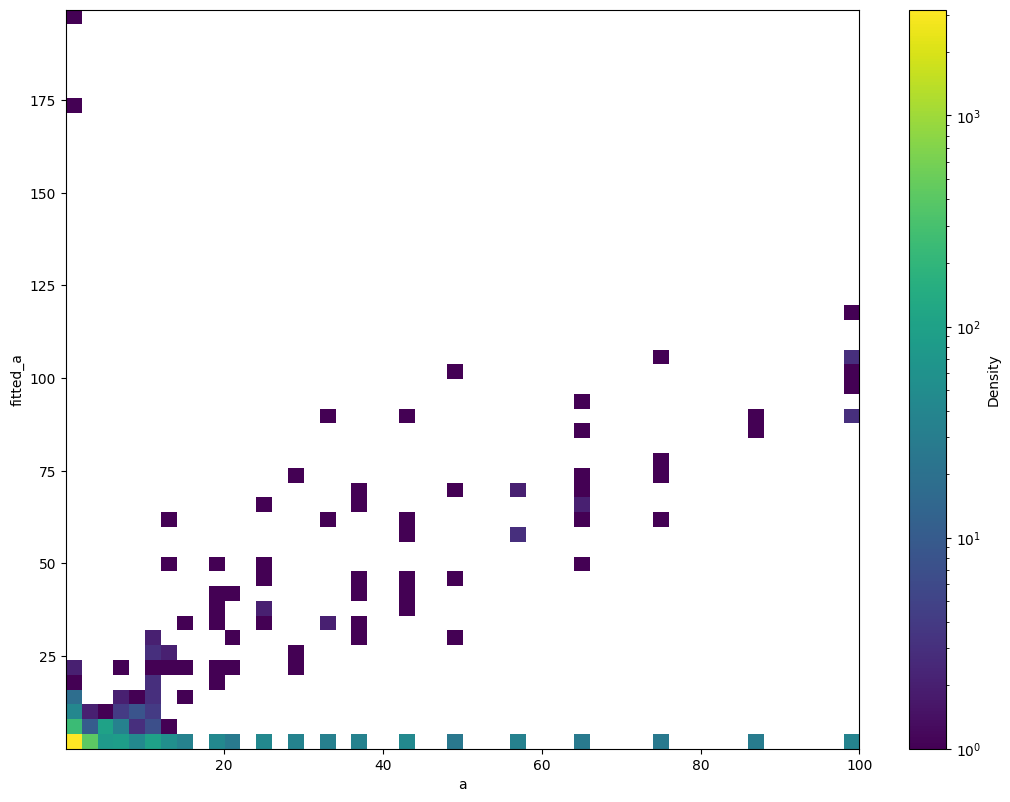

In [8]:
plot_density('a')

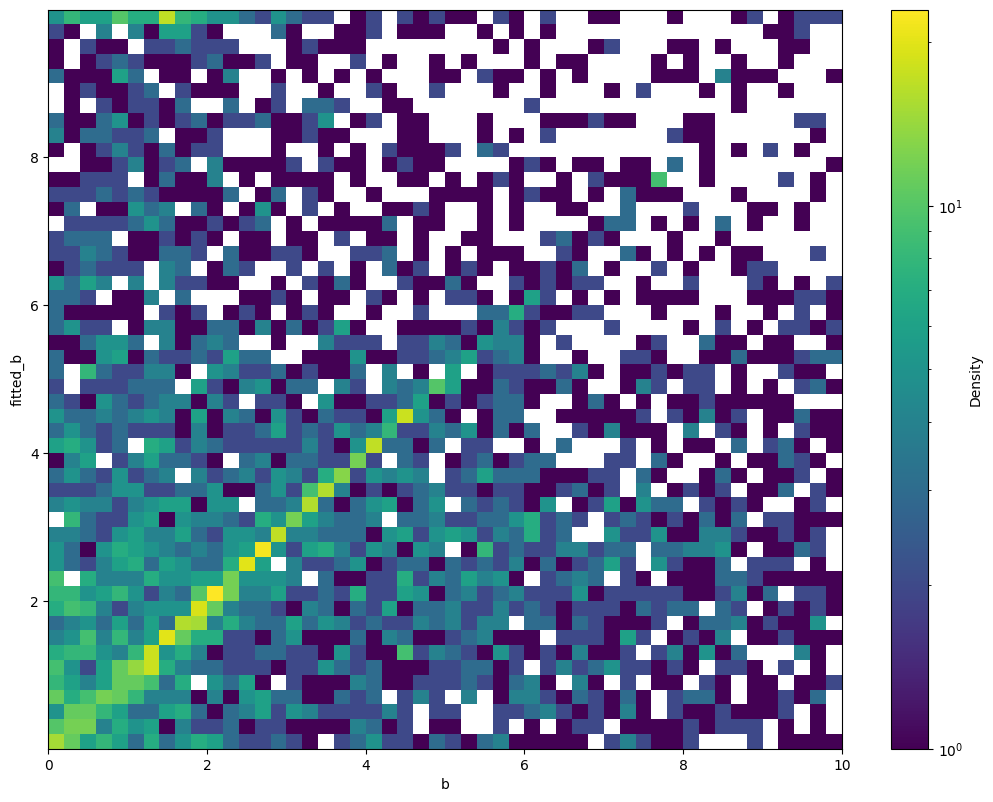

In [9]:
plot_density('b')

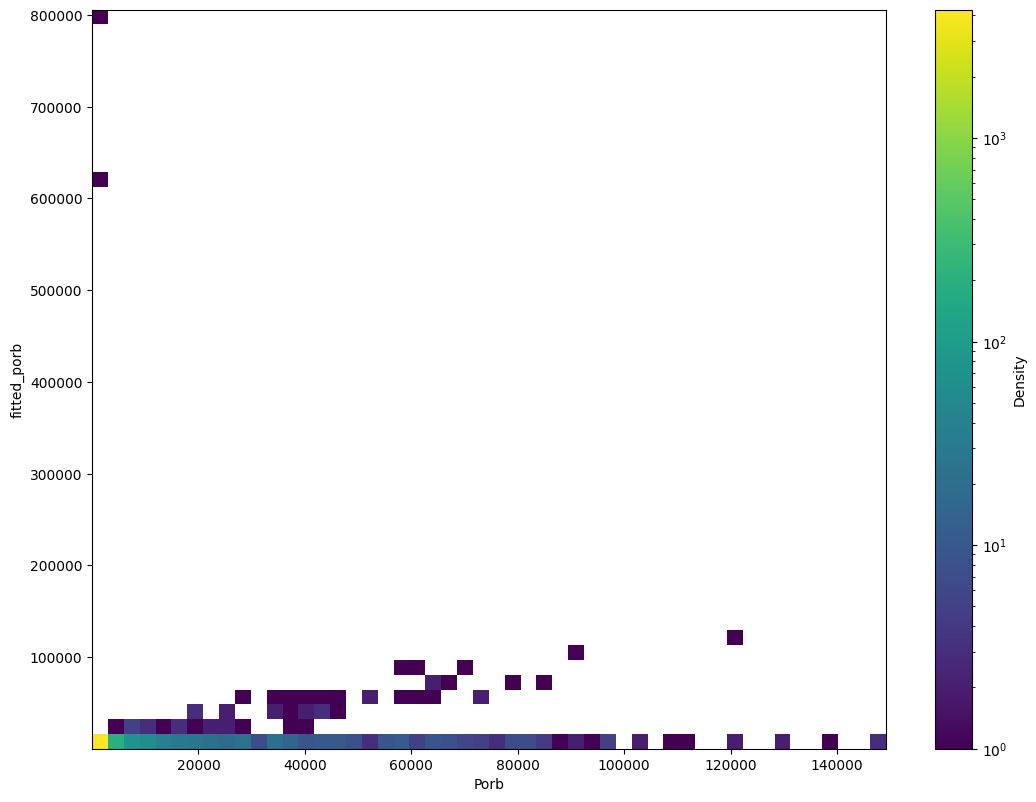

In [10]:
plot_density('Porb')

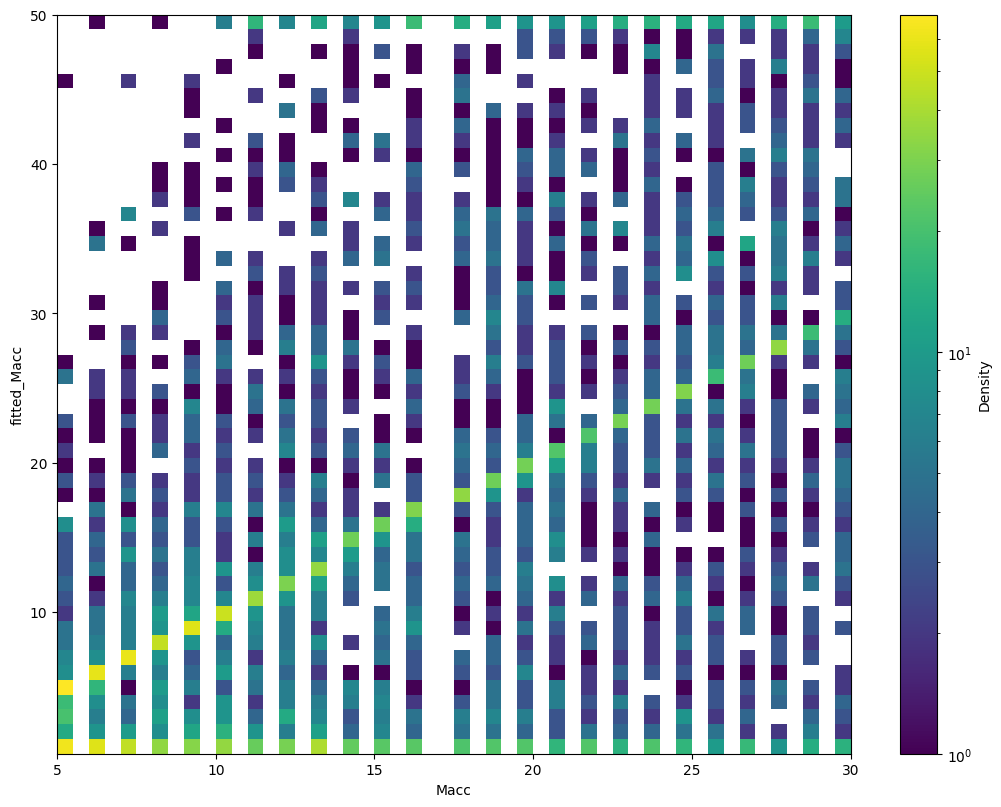

In [11]:
plot_density('Macc')

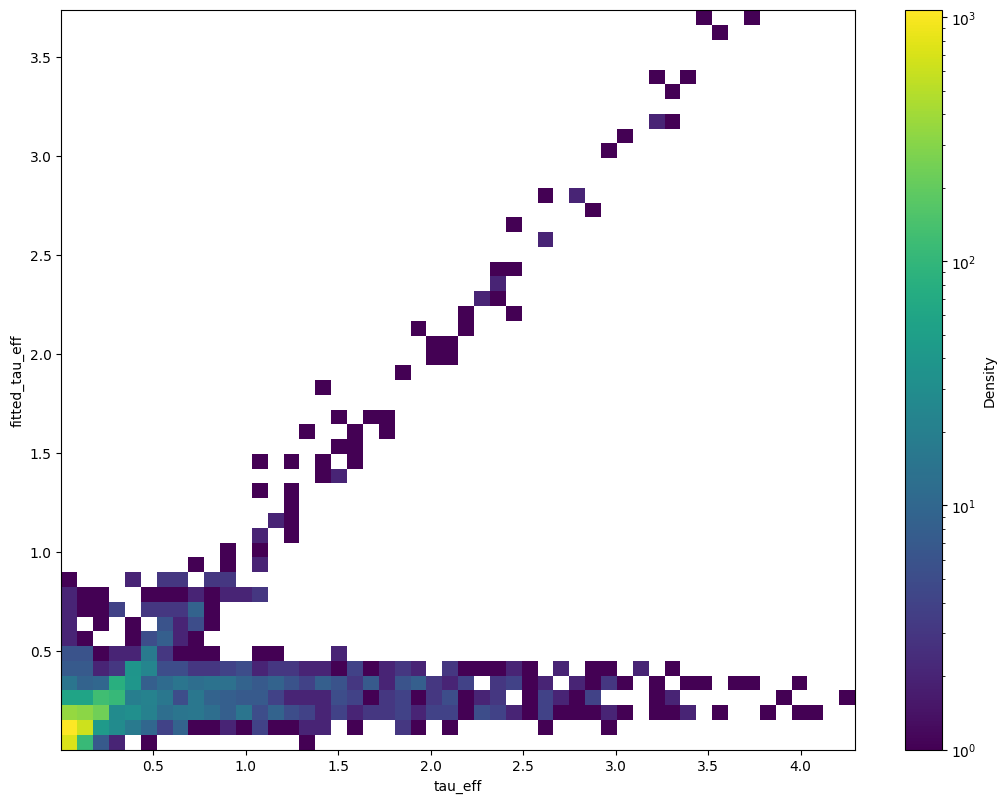

In [12]:
plot_density('tau_eff')

In [ ]:
def plot_relation(x, y='RV accuracy', logx=True, logy=True, bins=20):
    for cadence, cadence_group in results.groupby('cadence'):
        baselines = numpy.sort(cadence_group['baseline'].unique())
        fig, axes = pyplot.subplots(1, len(baselines), figsize=(6 * len(baselines), 5), sharey=True)
        if len(baselines) == 1:
            axes = [axes]
        for ax, baseline in zip(axes, baselines):
            subset = cadence_group[cadence_group['baseline'] == baseline]
            xdata = subset[x]
            ydata = subset[y]
            diff = numpy.abs(subset[x] - subset[params[x]]) / subset[x]
            # Bin edges
            if logx:
                xbins = numpy.logspace(numpy.log10(xdata.min()), numpy.log10(xdata.max()), bins + 1)
            else:
                xbins = numpy.linspace(xdata.min(), xdata.max(), bins + 1)
            if logy:
                ybins = numpy.logspace(numpy.log10(ydata.min()), numpy.log10(ydata.max()), bins + 1)
            else:
                ybins = numpy.linspace(ydata.min(), ydata.max(), bins + 1)
            # Digitize to get bin indices
            xinds = numpy.digitize(xdata, xbins) - 1
            yinds = numpy.digitize(ydata, ybins) - 1
            mean_diff = numpy.full((bins, bins), numpy.nan)
            for i in range(bins):
                for j in range(bins):
                    mask = (xinds == i) & (yinds == j)
                    if numpy.any(mask):
                        mean_diff[i, j] = diff[mask].mean()
            # Use log scale for colors
            mesh = ax.pcolormesh(
                xbins, ybins, mean_diff.T,
                cmap='viridis',
                norm=pyplot.matplotlib.colors.LogNorm(vmin=numpy.nanmin(mean_diff), vmax=numpy.nanmax(mean_diff))
            )
            ax.set_title(f'Cadence: {cadence}, Baseline: {baseline}')
            ax.set_xlabel(x)
            ax.set_ylabel(y)
            if logx:
                ax.set_xscale('log')
            if logy:
                ax.set_yscale('log')
            fig.colorbar(mesh, ax=ax, label='Mean absolute difference (%)')
        pyplot.tight_layout()
        pyplot.show()

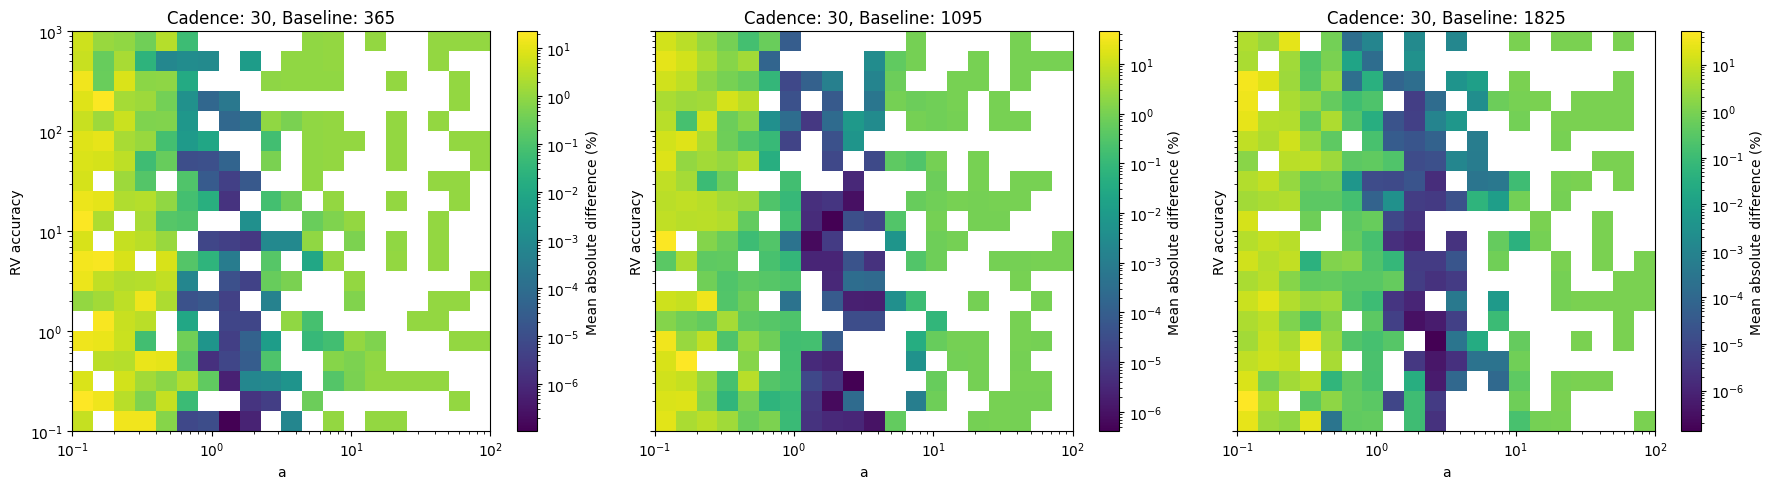

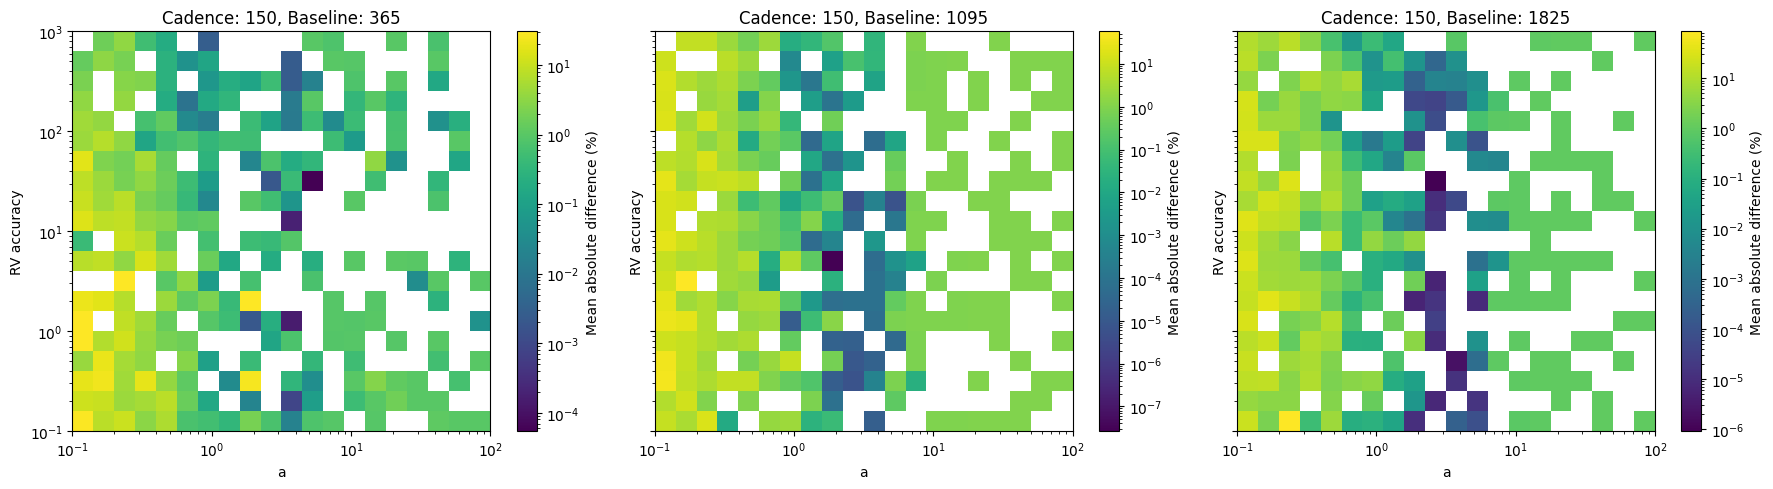

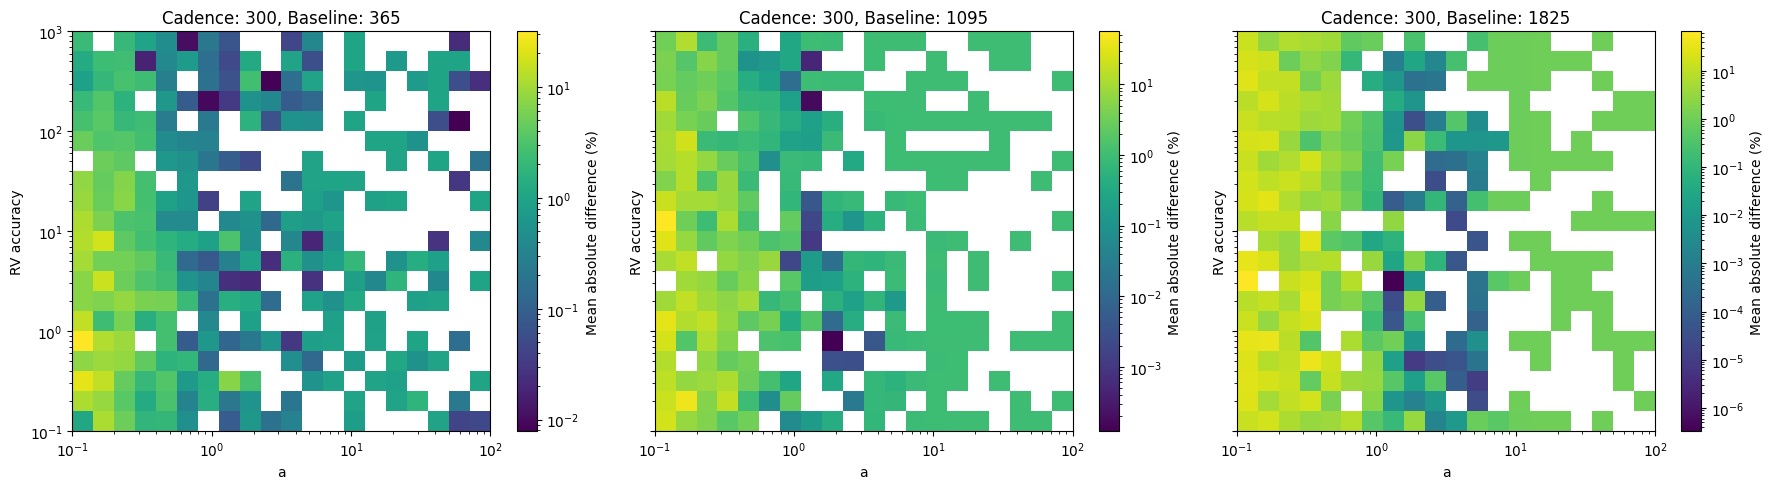

In [14]:
plot_relation('a')

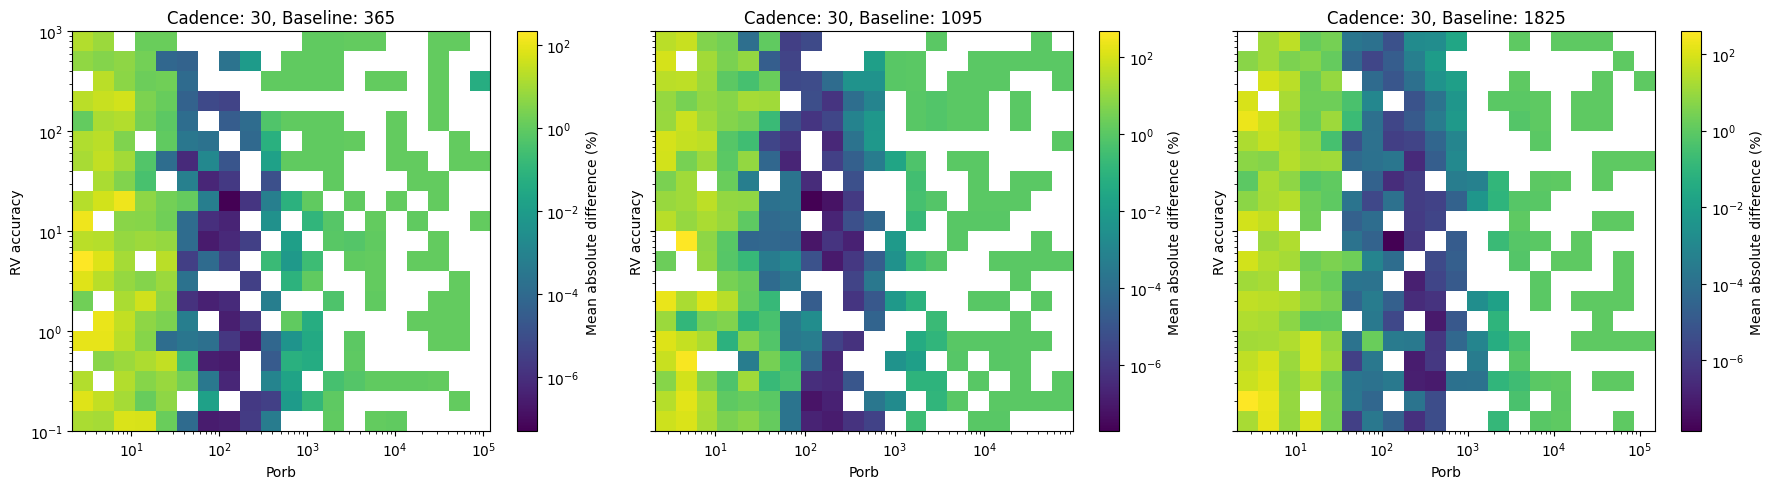

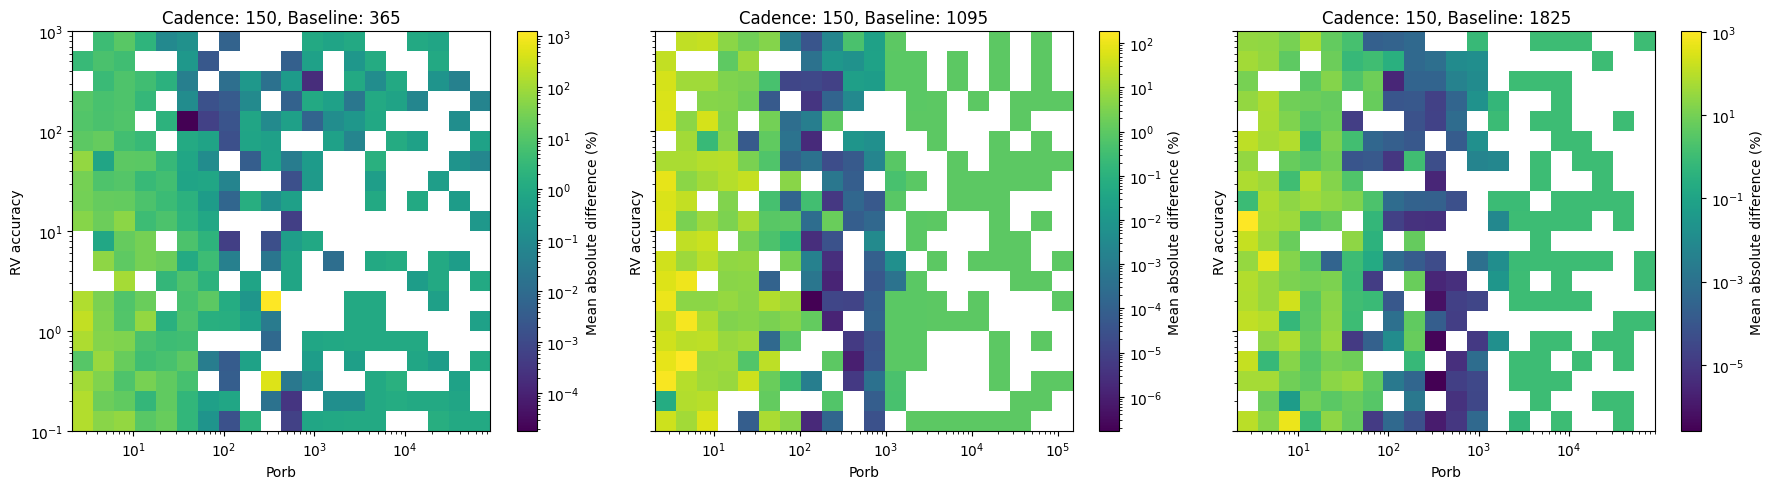

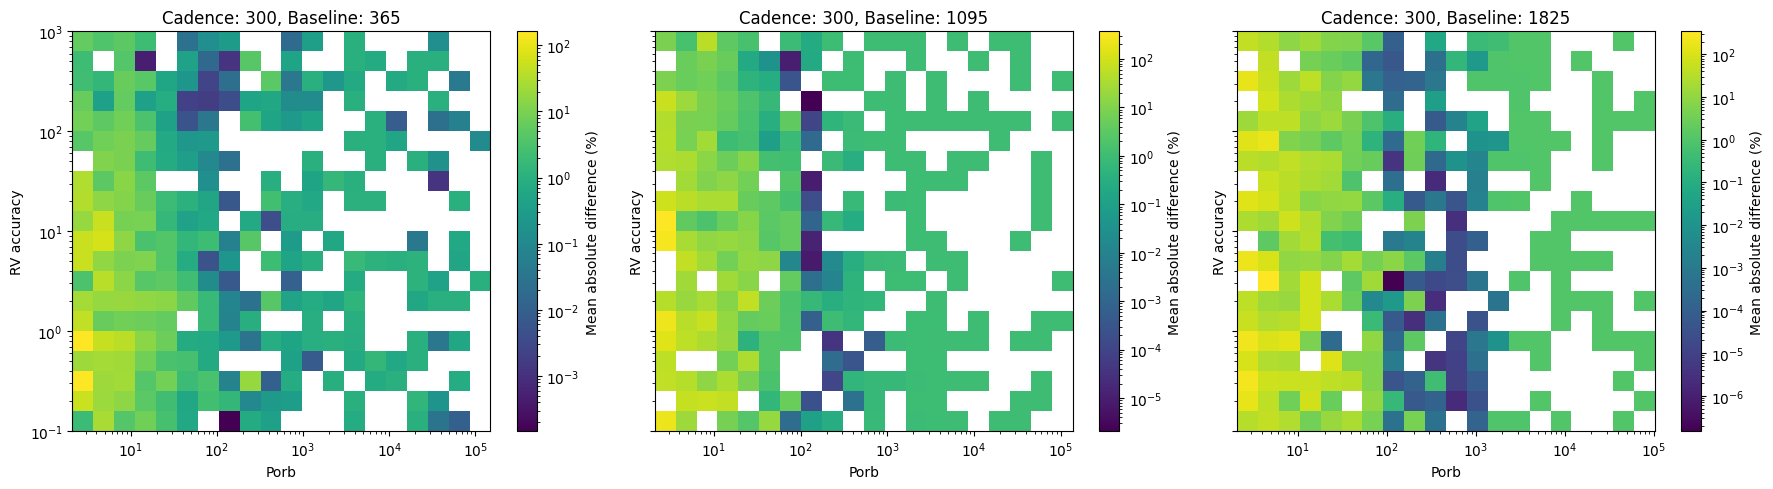

In [15]:
plot_relation('Porb')

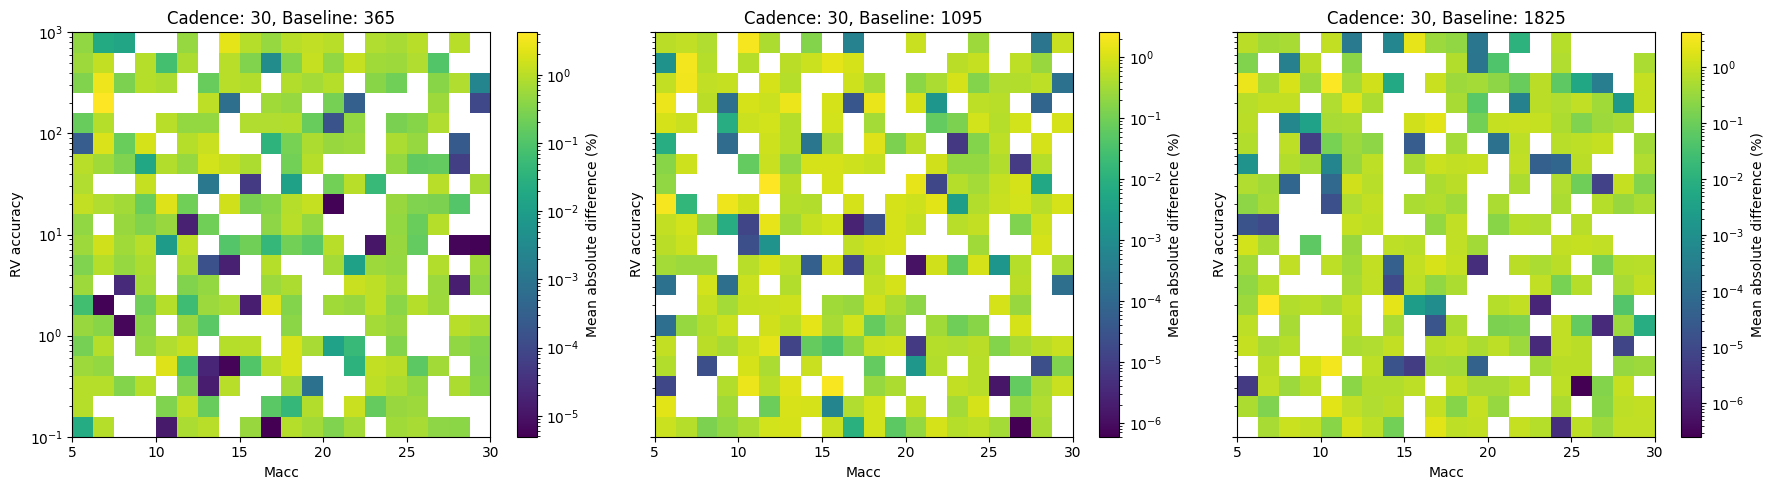

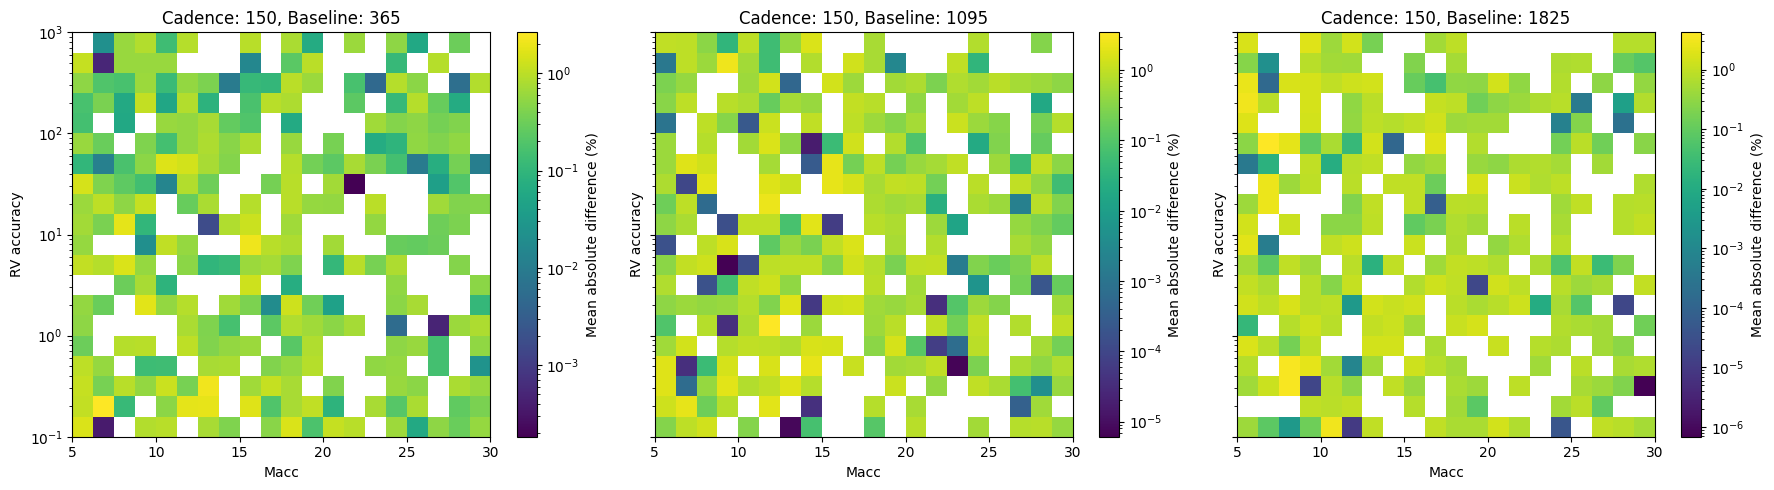

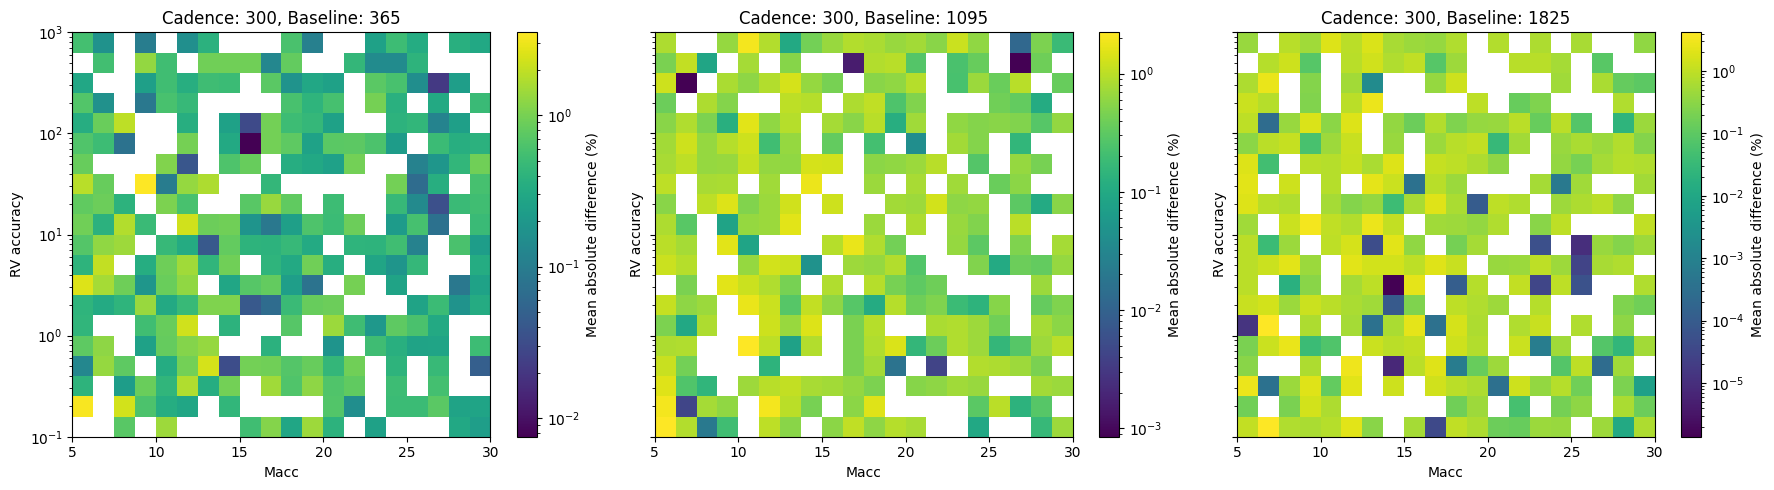

In [16]:
plot_relation('Macc', logx=False)

In [19]:
plot_relation('b', logx=False)

ValueError: Invalid vmin or vmax

<Figure size 1800x500 with 3 Axes>

ValueError: Invalid vmin or vmax

<Figure size 1800x500 with 3 Axes>

ValueError: Invalid vmin or vmax

<Figure size 1800x500 with 3 Axes>